# CellSTIC end-to-end tutorial on an external spatial RNA--ADT dataset

This notebook demonstrates the complete user workflow on a public dataset
that is not part of the CellSTIC manuscript analyses: source verification,
raw-data loading, quality control, modality assembly, model configuration,
training, result loading, and the supported downstream analyses.


Training is commented out by default. Run All analyzes the saved result without retraining.

## Dataset provenance and scope

We use the complete processed matrix for **SPOTS mouse spleen replicate 1**
from [GEO GSE198353](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE198353).
SPOTS jointly measures whole-transcriptome RNA and antibody-derived tags
(ADTs) at matched spatial barcodes. The associated study is Ben-Chetrit et al.,
*Nature Biotechnology* (2023),
[doi:10.1038/s41587-022-01536-3](https://doi.org/10.1038/s41587-022-01536-3).

The original GEO files are included under `example/data/` and occupy about
16 MiB. **No spots or molecular features are sampled:** all 2,653 filtered
tissue spots, 32,285 RNA features, and 21 ADT features are retained. The
checksums and direct source URLs are recorded in `data/manifest.json`.


## 1. Environment and paths

Run the notebook from either the repository root or `example/`. CPU is the
portable default. Limiting numerical-library threads makes this tutorial
reproducible across common workstation environments.


In [1]:
import os

os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")

import hashlib
import io
import json
import sys
import tarfile
from dataclasses import replace
from pathlib import Path

import anndata as ad
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import torch
from IPython.display import SVG, display

PROJECT_ROOT = Path.cwd().resolve()
while (
    PROJECT_ROOT != PROJECT_ROOT.parent
    and not (PROJECT_ROOT / "pipeline" / "cellstic.py").is_file()
):
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "pipeline" / "cellstic.py").is_file():
    raise RuntimeError("Start Jupyter from the CellSTIC repository root or example directory.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

DATA_DIR = PROJECT_ROOT / "example" / "data"
OUTPUT_DIR = PROJECT_ROOT / "example" / "cellstic"

from model.train import get_cellstic_config
from pipeline.analysis import Analysis
from pipeline.cellstic import run_cellstic

print("Project root:", PROJECT_ROOT)
print("External data:", DATA_DIR)
print("CellSTIC output:", OUTPUT_DIR)
print("Device: CPU (portable tutorial default)")


/home/wangshuai/anaconda3/envs/spaGem/lib/python3.8/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Project root: /home/wangshuai/project/CellSTIC-dup
External data: /home/wangshuai/project/CellSTIC-dup/example/data
CellSTIC output: /home/wangshuai/project/CellSTIC-dup/example/cellstic
Device: CPU (portable tutorial default)


## 2. Verify and load the original GEO files

The manifest check detects accidental truncation or modification. The 10x HDF5
file contains both molecular modalities; the Visium archive contains positions,
scale factors, and tissue images. Reading these source formats here makes the
raw-to-AnnData preprocessing explicit and reproducible.


In [2]:
def sha256(path, block_size=1024 * 1024):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for block in iter(lambda: handle.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()


manifest = json.loads((DATA_DIR / "manifest.json").read_text(encoding="utf-8"))
for filename, expected in manifest["files_sha256"].items():
    actual = sha256(DATA_DIR / filename)
    if actual != expected:
        raise ValueError(f"Checksum mismatch for {filename}: {actual}")

matrix_path = DATA_DIR / "GSE198353_spleen_rep_1_filtered_feature_bc_matrix.h5"
spatial_path = DATA_DIR / "GSE198353_spleen_replicate_1_spatial.tar.gz"
multiome = sc.read_10x_h5(matrix_path, gex_only=False)

with tarfile.open(spatial_path, "r:gz") as archive:
    positions = pd.read_csv(
        archive.extractfile("spatial/tissue_positions_list.csv"),
        header=None,
        index_col=0,
    )
    scale_factors = json.load(
        archive.extractfile("spatial/scalefactors_json.json")
    )
    lowres_image = plt.imread(
        io.BytesIO(archive.extractfile("spatial/tissue_lowres_image.png").read())
    )

positions.columns = [
    "in_tissue", "array_row", "array_col", "pixel_row", "pixel_col"
]
aligned_positions = positions.reindex(multiome.obs_names)
if aligned_positions.isna().any().any():
    raise ValueError("At least one molecular barcode has no spatial coordinate")
if not aligned_positions["in_tissue"].eq(1).all():
    raise ValueError("The filtered matrix unexpectedly contains an off-tissue barcode")

input_size = sum((DATA_DIR / name).stat().st_size for name in manifest["files_sha256"])
print(f"Verified {len(manifest['files_sha256'])} original files ({input_size / 2**20:.1f} MiB)")
print("Combined matrix:", multiome.shape)
display(multiome.var["feature_types"].value_counts().rename("features").to_frame())


Verified 2 original files (15.7 MiB)
Combined matrix: (2653, 32306)


/home/wangshuai/anaconda3/envs/spaGem/lib/python3.8/site-packages/anndata/_core/anndata.py:1840: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


,features
feature_types,
Gene Expression,32285
Antibody Capture,21


## 3. Quality control and aligned AnnData assembly

The deposited matrix is already a filtered feature-barcode matrix. We therefore
report QC summaries without applying another spot or feature filter. Duplicate
mouse gene symbols are made unique so that ligand/receptor names resolve
unambiguously; counts are otherwise unchanged. The two feature types are split
into aligned RNA and ADT AnnData objects, and full-resolution pixel coordinates
are stored in `rna.obsm['spatial']`.

CellSTIC later performs its standard modality-aware transformation in memory:
library-size normalization, log transformation, highly-variable-gene selection
and PCA for RNA, and CLR normalization plus PCA for ADT. Feature selection is
used only to construct the representation; the complete RNA matrix is retained
in the exported result.


In [3]:
multiome.var_names_make_unique()
is_rna = multiome.var["feature_types"].eq("Gene Expression").to_numpy()
is_adt = multiome.var["feature_types"].eq("Antibody Capture").to_numpy()
rna = multiome[:, is_rna].copy()
adt = multiome[:, is_adt].copy()

spatial_coordinates = aligned_positions[["pixel_col", "pixel_row"]].astype(np.float32)
rna.obsm["spatial"] = spatial_coordinates.to_numpy()
rna.layers["counts"] = rna.X.copy()
rna.uns["modality"] = "rna"
adt.uns["modality"] = "adt"

rna.obs["rna_total_counts"] = np.asarray(rna.X.sum(axis=1)).ravel()
rna.obs["rna_detected_genes"] = np.asarray((rna.X > 0).sum(axis=1)).ravel()
rna.obs["adt_total_counts"] = np.asarray(adt.X.sum(axis=1)).ravel()

if not rna.obs_names.equals(adt.obs_names):
    raise ValueError("RNA and ADT barcodes are not aligned")
expected = manifest["matrix_shape"]
observed = (rna.n_obs, rna.n_vars, adt.n_vars)
declared = (expected["spots"], expected["rna_features"], expected["adt_features"])
if observed != declared:
    raise ValueError(f"Unexpected dimensions: observed={observed}, expected={declared}")

display(pd.DataFrame({
    "modality": ["RNA", "ADT"],
    "spots": [rna.n_obs, adt.n_obs],
    "features": [rna.n_vars, adt.n_vars],
    "nonzero_fraction": [rna.X.nnz / np.prod(rna.shape), adt.X.nnz / np.prod(adt.shape)],
}).set_index("modality"))
display(rna.obs[["rna_total_counts", "rna_detected_genes", "adt_total_counts"]].describe().round(1))


,spots,features,nonzero_fraction
modality,,,
RNA,2653,32285,0.103921
ADT,2653,21,0.998241


,rna_total_counts,rna_detected_genes,adt_total_counts
count,2653.0,2653.0,2653.0
mean,7762.3,3355.1,1450.2
std,2557.2,741.9,374.4
min,42.0,33.0,6.0
25%,5971.0,2877.0,1250.0
50%,7397.0,3320.0,1464.0
75%,9575.0,3917.0,1687.0
max,16823.0,5366.0,2672.0


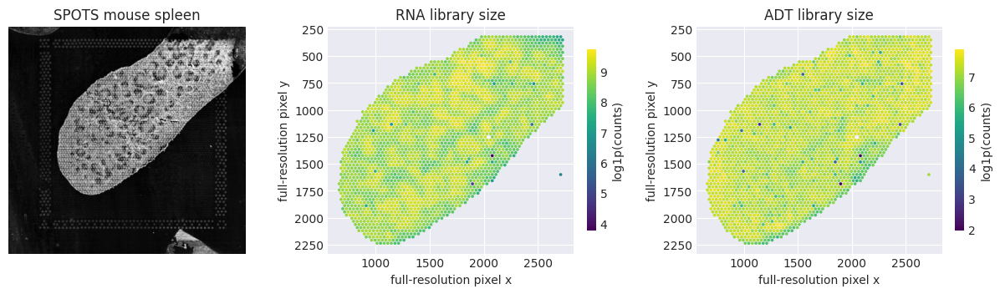

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), constrained_layout=True)
scale = float(scale_factors["tissue_lowres_scalef"])
axes[0].imshow(lowres_image)
axes[0].scatter(
    spatial_coordinates["pixel_col"] * scale,
    spatial_coordinates["pixel_row"] * scale,
    s=2, c="white", alpha=0.45, linewidths=0,
)
axes[0].set_title("SPOTS mouse spleen")
axes[0].axis("off")

for axis, column, title in zip(
    axes[1:],
    ["rna_total_counts", "adt_total_counts"],
    ["RNA library size", "ADT library size"],
):
    points = axis.scatter(
        spatial_coordinates["pixel_col"], spatial_coordinates["pixel_row"],
        c=np.log1p(rna.obs[column]), s=7, cmap="viridis", linewidths=0,
    )
    axis.set_title(title)
    axis.set_aspect("equal")
    axis.invert_yaxis()
    axis.set_xlabel("full-resolution pixel x")
    axis.set_ylabel("full-resolution pixel y")
    fig.colorbar(points, ax=axis, label="log1p(counts)", shrink=0.8)
plt.show()


## 4. Configure CellSTIC and declare ligand--receptor pairs

The `human_skin` preset supplies a two-modality RNA--ADT architecture; the
dataset-independent graph and optimization settings below make a complete CPU
run practical for a tutorial. Five spatial domains follow the biological
resolution used in the original SPOTS analysis. The six mouse ligand--receptor
pairs are passed directly as a small, transparent dictionary—there is no hidden
mapping or database-conversion helper.

The reduced epoch counts are intended for software demonstration and should not
be treated as a converged scientific analysis. We export raw model probabilities
(`postprocess_before_aggregation=False`) so that every declared channel can be
inspected in this teaching run; plots are descriptive hypotheses rather than
FDR-supported molecular interactions.


In [5]:
ligand_receptor_map = {
    "Cxcl12": ["Cxcr4"],
    "Ccl19": ["Ccr7"],
    "Ccl21a": ["Ccr7"],
    "Il16": ["Cd4"],
    "App": ["Cd74"],
    "Tnf": ["Tnfrsf1a"],
}
missing_lr_genes = sorted(
    ({*ligand_receptor_map} | {r for values in ligand_receptor_map.values() for r in values})
    - set(rna.var_names)
)
if missing_lr_genes:
    raise ValueError(f"Missing ligand/receptor genes: {missing_lr_genes}")

base_config = get_cellstic_config("human_skin")
config = replace(
    base_config,
    model=replace(
        base_config.model,
        graph=replace(
            base_config.model.graph,
            cluster_top_k=10,
            cluster_size=48,
            knn_top_k=10,
            expression_percentile=90.0,
            n_spots=6,
            max_spatial_neighbors=24,
        ),
    ),
    train=replace(
        base_config.train,
        feat=replace(
            base_config.train.feat,
            epochs=40,
            n_clusters=5,
            clustering_iterations=3,
        ),
        ccc=replace(
            base_config.train.ccc,
            epochs=20,
            sampling_rate=0.3,
            max_masked_edges_per_channel=128,
            graph_batch_size=512,
        ),
    ),
)

print("Feature epochs:", config.train.feat.epochs)
print("CCC epochs per hierarchy level:", config.train.ccc.epochs)
print("Spatial domains:", config.train.feat.n_clusters)
print("Ligand--receptor candidates:", ligand_receptor_map)


Feature epochs: 40
CCC epochs per hierarchy level: 20
Spatial domains: 5
Ligand--receptor candidates: {'Cxcl12': ['Cxcr4'], 'Ccl19': ['Ccr7'], 'Ccl21a': ['Ccr7'], 'Il16': ['Cd4'], 'App': ['Cd74'], 'Tnf': ['Tnfrsf1a']}


## 5. Train and export (optional)

Training is commented out by default. Uncomment the following cell only to
train a fresh model and replace the local result under `example/cellstic/`.
The call performs modality-aware preprocessing, sparse graph construction,
feature integration, domain learning, CCC training, checkpointing, and export.
Run All leaves the saved fit unchanged.

In [6]:
# result = run_cellstic(
#     [rna, adt],
#     config,
#     output_path=OUTPUT_DIR,
#     ligand_receptor_map=ligand_receptor_map,
#     modality_types=["rna", "adt"],
#     auto_n_clusters=5,
#     run_ccc=True,
#     postprocess_before_aggregation=False,
#     device=torch.device("cpu"),
# )

## 6. Load and inspect the saved model result

The exported AnnData retains the full processed RNA matrix, raw counts,
coordinates, integrated embedding (`obsm['out']`), domain labels
(`obs['cluster']`), configuration/provenance metadata, and sparse hierarchy/CCC
matrices. If the file is absent, run the training cell above once.


In [7]:
result_path = OUTPUT_DIR / "out" / "out.h5ad"
if not result_path.is_file():
    raise FileNotFoundError(
        f"{result_path} is missing; uncomment and run the training cell first"
    )
exported = ad.read_h5ad(result_path)
ccc_keys = sorted(key for key in exported.obsp if key.startswith("cellstic_L"))

print(exported)
print("Domain sizes:", exported.obs["cluster"].value_counts().sort_index().to_dict())
print("Integrated representation:", exported.obsm["out"].shape)
print("Sparse hierarchy/CCC matrices:", len(ccc_keys))
print("Result file:", result_path.relative_to(PROJECT_ROOT))


AnnData object with n_obs × n_vars = 2653 × 32285
    obs: 'rna_total_counts', 'rna_detected_genes', 'adt_total_counts', 'n_genes_by_counts', 'total_counts', 'cluster'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm'
    uns: 'cellstic', 'cellstic_preprocessing', 'hvg', 'log1p', 'modality'
    obsm: 'feat', 'out', 'spatial'
    layers: 'counts'
    obsp: 'cellstic_L1_lr_root', 'cellstic_L2_lr_App_Cd74', 'cellstic_L2_lr_Ccl19_Ccr7', 'cellstic_L2_lr_Ccl21a_Ccr7', 'cellstic_L2_lr_Cxcl12_Cxcr4', 'cellstic_L2_lr_Il16_Cd4', 'cellstic_L2_lr_Tnf_Tnfrsf1a'
Domain sizes: {'0': 696, '1': 638, '2': 576, '3': 420, '4': 323}
Integrated representation: (2653, 100)
Sparse hierarchy/CCC matrices: 7
Result file: example/cellstic/out/out.h5ad


## 7. Analyze spatial domains

The spatial map shows the five saved RNA–ADT domains in measured tissue
coordinates. The domain map uses the existing spatial visualizer; subsequent
communication and hierarchy analyses use `pipeline.analysis.Analysis`.

In [8]:
from utils.analysis.figure_export import show_image_row

from utils.metrics.spatial_viz import SpatialVisualizer
analysis = Analysis.from_result(exported, output_path=OUTPUT_DIR)
spatial = ad.AnnData(obs=exported.obs.copy(), obsm={"spatial": exported.obsm["spatial"]})
spatial.obs["cluster"] = pd.Categorical(spatial.obs["cluster"].astype(str))
(OUTPUT_DIR / "domain").mkdir(parents=True, exist_ok=True)
SpatialVisualizer.generate_spatial_domain_visualization(
    spatial, save_path=OUTPUT_DIR / "domain/spatial_domain.svg", size_multiplier=0.85)
show_image_row([OUTPUT_DIR / "domain/spatial_domain.svg"])


Visualizing 2653 points with 5 domains in grid style
  Calculated min nearest neighbor distance: 33.0000
  Square size (base * 0.85): 33.6600
  Direct visualization: 2653 points, each point gets its own square


/home/wangshuai/anaconda3/envs/spaGem/lib/python3.8/site-packages/anndata/_core/anndata.py:121: ImplicitModificationWarning: Transforming to str index.
  warnings.warn("Transforming to str index.", ImplicitModificationWarning)


Spatial domain visualization (grid style) saved to /home/wangshuai/project/CellSTIC-dup/example/cellstic/domain/spatial_domain.svg


## 8. Analyze representative communication channels

The selected channels cover chemokine-guided immune organization
(`Cxcl12:Cxcr4` and `Ccl21a:Ccr7`) and antigen-presenting-cell-associated
signaling (`App:Cd74`). For each channel, the strength-colored and
domain-annotated spatial maps are displayed side by side. Scores are model
hypotheses on spatially eligible edges, not direct observations of binding or
causal signaling.


In [9]:
selected_lr = ["Cxcl12:Cxcr4", "Ccl21a:Ccr7", "App:Cd74"]
ccc_dir = analysis.plot_spatial_ccc(
    lr_filter=selected_lr,
    threshold=0.5,
    domain_key="cluster",
    max_outgoing_edges_per_node=1,
    max_incoming_edges_per_node=1,
)

for prefix in ["lr_spatial_", "lr_spatial_region_"]:
    figures = [ccc_dir / (prefix + pair.replace(":", "_") + ".svg") for pair in selected_lr]
    show_image_row(figures, labels=selected_lr)

Found 3 valid ligand-receptor pairs


Found 3 valid ligand-receptor pairs


## 9. Summarize the learned hierarchy by spatial-domain pairs

The balanced ligand--receptor hierarchy is aggregated over sender and receiver
domains. The thresholds below are descriptive display choices for this
tutorial; substantive analyses should prespecify or sensitivity-test them.


In [10]:
hierarchy_dir = analysis.plot_hierarchy(
    group_by="domain",
    group_key="cluster",
    threshold=0.5,
    min_count_threshold=20,
    min_width_fraction=0.02,
)
representative_pairs = sorted(
    (hierarchy_dir / "alluvial" / "domain_pairs").glob("*.svg")
)[:2]
hierarchy_bars = sorted(
    (hierarchy_dir / "alluvial" / "domain_bar").glob("*.svg")
)
show_image_row(representative_pairs)
show_image_row(hierarchy_bars)


Sender/receiver stacked bar saved to /home/wangshuai/project/CellSTIC-dup/example/cellstic/alluvial/domain_bar/lr_pair_stacked_bar_level_2.svg
